In [1]:
import math
import os
import numpy as np
import pandas as pd
from scipy.stats import entropy
from collections import Counter
import matplotlib.pyplot as plt
import scipy.stats as stats

In [2]:
import os
from dotenv import load_dotenv
from pathlib import Path

# Como o notebook está em 'corretor/src/3_avaliacao' e o .env em 'corretor',
# precisamos voltar duas pastas (../..) para achar o arquivo.
env_path = Path('../../.env')

# Carrega o arquivo explicitamente
load_dotenv(dotenv_path=env_path)

True

In [3]:
PATH_BASE_ANONIMIZADA_CORRETOR = os.getenv("PATH_BASE_ANONIMIZADA_CORRETOR")
PATH_BASE_ENTROPIA_CORRETOR = os.getenv("PATH_BASE_ENTROPIA_CORRETOR")

In [4]:
base_relato_anon = pd.read_csv(PATH_BASE_ANONIMIZADA_CORRETOR)

É realizado o cálculo de entropia dos textos em claro e anonimizados, após isso realizada a comparação dos resultados obtidos.

- Foi criada uma tabela com o resultado da entropia de cada texto e realizada
- Realizado o cálculo da média de cada conjunto: Média dos resultados dos textos em claro e média dos resultados dos textos anonimizados. Assim podendo quantificar o impacto.
- Também foi realizado o cálculo do desvio padrão para mensurar diferença das entropias.

A entropia é calulada com base na probabilidade da ocorrência de cada caracter no texto. O resultado obtido da probabilidade de cada caracter é inserido para calculo da entropia utilizando a biblioteca entropy do scipy.stats que calcula a entropia com base na formula da entropia de shannon ( entropia da informação ).


In [5]:
def calculate_text_entropy(text, base=None):
    char_counts = Counter(text)
    total_chars = sum(char_counts.values())
    probabilities = np.array([count / total_chars for count in char_counts.values()])

    return entropy(probabilities, base=base)

resultado texto unicos

In [6]:
text = base_relato_anon['relato'].iloc[0]
text_anon = base_relato_anon['relato_anon'].iloc[0]

entropia do texto original

In [7]:
entropia = calculate_text_entropy(text, base=2)
entropia

np.float64(4.328201075976756)

entropia do texto anonimizado

In [8]:
entropia = calculate_text_entropy(text_anon, base=2)
entropia

np.float64(4.187402046362407)

resultado sobre toda a base de BOs

In [9]:
base_relato_anon['entrpy_result_orig'] = base_relato_anon['relato'].apply(lambda x: calculate_text_entropy(x, base=2))

In [10]:
base_relato_anon['entrpy_result_anon'] = base_relato_anon['relato_anon'].apply(lambda x: calculate_text_entropy(x, base=2))

In [11]:
save_df = base_relato_anon[["n_bop", "entrpy_result_orig", "entrpy_result_anon"]]

In [12]:
save_df = save_df.rename(columns={"entrpy_result_orig":"corretor_text_orig", "entrpy_result_anon":"Entropy Corretor"})

In [13]:
save_df.to_csv(PATH_BASE_ENTROPIA_CORRETOR, index=False)

In [14]:
save_df

,n_bop,corretor_text_orig,Entropy Corretor
0,1,4.328201,4.187402
1,2,4.399838,4.297320
2,3,4.350131,4.191190
3,4,4.326459,4.268169
4,5,4.331277,4.094836
...,...,...,...
1881,1882,4.322932,4.095629
1882,1883,4.351737,4.119345
1883,1884,4.392405,4.065020
1884,1885,4.366220,4.081523


### Verificando se há outliers

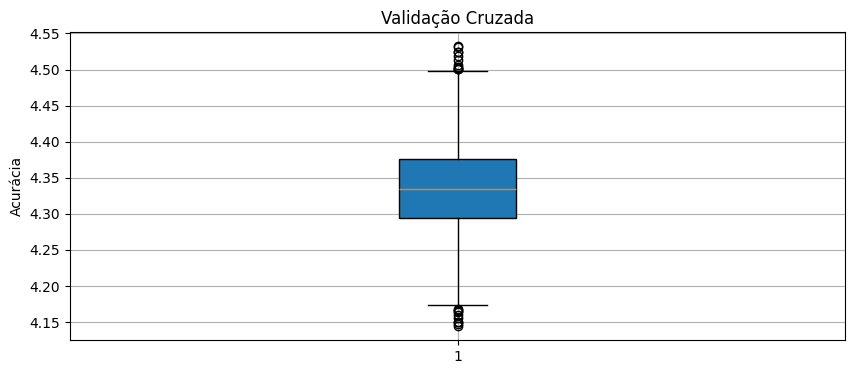

In [15]:
plt.figure(figsize=(10, 4))
plt.boxplot(base_relato_anon['entrpy_result_orig'], patch_artist=True)
plt.grid(True)
plt.title('Validação Cruzada')
plt.ylabel('Acurácia')
plt.show()


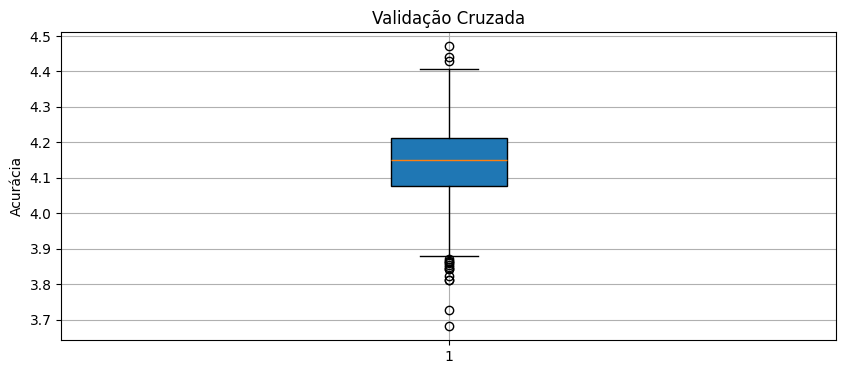

In [16]:
plt.figure(figsize=(10, 4))
plt.boxplot(base_relato_anon['entrpy_result_anon'], patch_artist=True)
plt.grid(True)
plt.title('Validação Cruzada')
plt.ylabel('Acurácia')
plt.show()


#### Teste Shapiro para verificação da distribuição

In [17]:
shapiro_orig = stats.shapiro(base_relato_anon["entrpy_result_orig"])
shapiro_anon = stats.shapiro(base_relato_anon["entrpy_result_anon"])
print(f"Teste de Shapiro-Wilk para entrpy_result_orig: p-valor={shapiro_orig.pvalue}")
print(f"Teste de Shapiro-Wilk para entrpy_result_anon: p-valor={shapiro_anon.pvalue}")

Teste de Shapiro-Wilk para entrpy_result_orig: p-valor=0.0055274492069296716
Teste de Shapiro-Wilk para entrpy_result_anon: p-valor=6.415372409010726e-06


#### Teste de Wilcoxon - verificação da significancia

recomendação para utilização desse teste em casos que houvesse outliers - o que foi visto nas células acima

In [18]:
w_stat, p_value_w = stats.wilcoxon(base_relato_anon["entrpy_result_orig"], base_relato_anon["entrpy_result_anon"])

In [19]:
print(f"{w_stat} \n{p_value_w}")

108.0 
1.461269775893464e-309


#### Teste T - para calculo de significancia também

In [20]:
t_stat, p_value_t = stats.ttest_rel(base_relato_anon["entrpy_result_orig"], base_relato_anon["entrpy_result_anon"])

In [21]:
print(f"{w_stat} \n{p_value_w}")

108.0 
1.461269775893464e-309


#### pedi pro chatgpt me ajudar a interpretar ele criou isso aqui KKKKKKKKK

In [22]:
alpha = 0.05
if p_value_t < alpha:
    print("A diferença entre as entropias é estatisticamente significativa (Teste t).")
else:
    print("A diferença entre as entropias NÃO é estatisticamente significativa (Teste t).")

if p_value_w < alpha:
    print("A diferença entre as entropias é estatisticamente significativa (Teste de Wilcoxon).")
else:
    print("A diferença entre as entropias NÃO é estatisticamente significativa (Teste de Wilcoxon).")

A diferença entre as entropias é estatisticamente significativa (Teste t).
A diferença entre as entropias é estatisticamente significativa (Teste de Wilcoxon).


Media dos valores

In [23]:
base_relato_anon['entrpy_result_orig'].values.mean()

np.float64(4.335943376134726)

In [24]:
base_relato_anon['entrpy_result_anon'].values.mean()

np.float64(4.14292412605304)

In [25]:
np.std(base_relato_anon['entrpy_result_orig'].values)

np.float64(0.06017793423726789)

In [26]:
np.std(base_relato_anon['entrpy_result_anon'].values)

np.float64(0.10020379622596746)